# 01 - Exploratory Data Analysis (EDA)

This notebook performs exploratory data analysis on raw financial time series data.

## Objectives
- Load and inspect raw OHLCV data
- Analyze data quality and missing values
- Visualize price distributions and trends
- Compute basic statistics
- Check for stationarity

In [1]:
# Standard imports
import sys
from pathlib import Path

# Fix statistics module shadowing issue - MUST be done before any imports that use statistics
# The project has a 'statistics' folder that shadows Python's built-in statistics module
# Clear any cached statistics module
for mod_name in list(sys.modules.keys()):
    if mod_name == 'statistics' or mod_name.startswith('statistics.'):
        del sys.modules[mod_name]

# Get project root
project_root = Path.cwd().parent if 'notebooks' in str(Path.cwd()) else Path.cwd()

# Temporarily remove project paths that contain 'statistics' folder during seaborn import
original_path = sys.path.copy()
sys.path = [p for p in sys.path if not (Path(p) / 'statistics').exists() or 'site-packages' in p]

# Import seaborn FIRST (it needs Python's statistics module)
import seaborn as sns

# Now restore path and add project root for our imports
sys.path = original_path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Project imports
from src.utils.config import Config
from src.data.loader import DataLoader

# Configuration
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
%matplotlib inline

In [2]:
# Load configuration
config = Config.load()
loader = DataLoader(config)
print("Available assets:")
for category, category_assets in config.assets['assets'].items():
    print(f"\n{category.upper()}:")
    for asset_key, asset_info in category_assets.items():
        print(f"  - {asset_key}: {asset_info['name']} ({asset_info['timeframe']})")

Available assets:

COMMODITY:
  - crudeoil: Crude Oil (D1)
  - gold: Gold (D1)

CRYPTO:
  - bitcoin: Bitcoin/USD (D1)
  - ethereum: Ethereum/USD (D1)

EQUITY:
  - apple: Apple Inc. (D1)
  - microsoft: Microsoft Corp. (D1)

FOREX:
  - eurusd: EUR/USD (D1)
  - usdjpy: USD/JPY (D1)

INDEX:
  - nasdaq: NASDAQ (D1)
  - sp500: S&P 500 (D1)


## 1. Load Raw Data

In [3]:
# Select asset for analysis
ASSET = 'apple'

# Load raw data
df = loader.load(ASSET, use_interim=False)

print(f"Dataset: {ASSET}")
print(f"Shape: {df.shape}")
print(f"Date Range: {df.index.min()} to {df.index.max()}")
print(f"\nColumn Types:")
print(df.dtypes)

2026-02-02 03:17:29 | INFO | Loading data from C:\Users\Nabeel\Desktop\New folder\indicator_impact_forecasting\data\raw\equity\apple\Apple_daily.csv
2026-02-02 03:17:29 | INFO | Loaded 4024 rows with columns: ['Open', 'High', 'Low', 'Close', 'Volume']
Dataset: apple
Shape: (4024, 5)
Date Range: 2010-01-04 00:00:00 to 2025-12-31 00:00:00

Column Types:
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


In [4]:
# Display first and last rows
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

First 5 rows:


,Open,High,Low,Close,Volume
Date,,,,,
2010-01-04,6.418383,6.433079,6.369498,6.400988,493729600
2010-01-05,6.429480,6.465769,6.395590,6.436078,601904800
2010-01-06,6.327212,6.454974,6.320614,6.429482,552160000
2010-01-07,6.315513,6.358101,6.269627,6.350603,477131200
2010-01-08,6.357501,6.358101,6.269928,6.307116,447610800



Last 5 rows:


,Open,High,Low,Close,Volume
Date,,,,,
2025-12-24,273.809998,275.429993,272.200012,272.339996,17910600
2025-12-26,273.399994,275.369995,272.859985,274.160004,21521800
2025-12-29,273.760010,274.359985,272.350006,272.690002,23715200
2025-12-30,273.079987,274.079987,272.279999,272.809998,22139600
2025-12-31,271.859985,273.679993,271.750000,273.059998,27293600


## 2. Data Quality Analysis

In [5]:
# Check for missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})

print("Missing Values Analysis:")
display(missing_df)

Missing Values Analysis:


,Missing Count,Missing %
Open,0,0.0
High,0,0.0
Low,0,0.0
Close,0,0.0
Volume,0,0.0


In [6]:
# Check for duplicates
duplicates = df.index.duplicated().sum()
print(f"Duplicate timestamps: {duplicates}")

# Check for gaps in time series
time_diffs = df.index.to_series().diff()
expected_freq = time_diffs.mode()[0]
gaps = time_diffs[time_diffs > expected_freq * 2]

print(f"\nExpected frequency: {expected_freq}")
print(f"Gaps found: {len(gaps)}")

if len(gaps) > 0:
    print("\nLargest gaps:")
    display(gaps.nlargest(5))

Duplicate timestamps: 0

Expected frequency: 1 days 00:00:00
Gaps found: 834

Largest gaps:


Date
2012-10-31   5 days
2010-01-19   4 days
2010-02-16   4 days
2010-04-05   4 days
2010-06-01   4 days
Name: Date, dtype: timedelta64[ns]

In [7]:
# Check for invalid values
print("Data Integrity Checks:")

# Negative prices
negative_prices = (df[['Open', 'High', 'Low', 'Close']] < 0).any().any()
print(f"  Negative prices: {negative_prices}")

# High < Low
invalid_hl = (df['High'] < df['Low']).sum()
print(f"  High < Low occurrences: {invalid_hl}")

# Close outside High-Low range
close_outside = ((df['Close'] > df['High']) | (df['Close'] < df['Low'])).sum()
print(f"  Close outside H-L range: {close_outside}")

# Zero volume
if 'Volume' in df.columns:
    zero_volume = (df['Volume'] == 0).sum()
    print(f"  Zero volume bars: {zero_volume}")

Data Integrity Checks:
  Negative prices: False
  High < Low occurrences: 0
  Close outside H-L range: 0
  Zero volume bars: 0


## 3. Statistical Summary

In [8]:
# Basic statistics
print("Descriptive Statistics:")
display(df.describe())

Descriptive Statistics:


,Open,High,Low,Close,Volume
count,4024.000000,4024.000000,4024.000000,4024.000000,4.024000e+03
mean,77.510779,78.277149,76.671549,77.446200,2.190006e+08
std,75.030483,75.756002,74.225112,74.949922,2.154860e+08
min,5.759780,5.878244,5.705796,5.769376,1.791060e+07
25%,18.227583,18.421395,18.076132,18.247222,7.765910e+07
50%,38.882465,39.325300,38.358306,38.840823,1.307822e+08
75%,142.931786,144.468231,141.242501,142.785863,2.899995e+08
max,286.190002,288.619995,283.299988,286.200012,1.880998e+09


In [9]:
# Calculate returns
df['returns'] = df['Close'].pct_change()
df['log_returns'] = np.log(df['Close'] / df['Close'].shift(1))

# Return statistics
returns = df['returns'].dropna()

print("Return Statistics:")
print(f"  Mean: {returns.mean():.6f}")
print(f"  Std Dev: {returns.std():.6f}")
print(f"  Skewness: {returns.skew():.4f}")
print(f"  Kurtosis: {returns.kurtosis():.4f}")
print(f"  Min: {returns.min():.6f}")
print(f"  Max: {returns.max():.6f}")

Return Statistics:
  Mean: 0.001105
  Std Dev: 0.018540
  Skewness: 0.0916
  Kurtosis: 6.4012
  Min: -0.140904
  Max: 0.171182


## 4. Visualizations

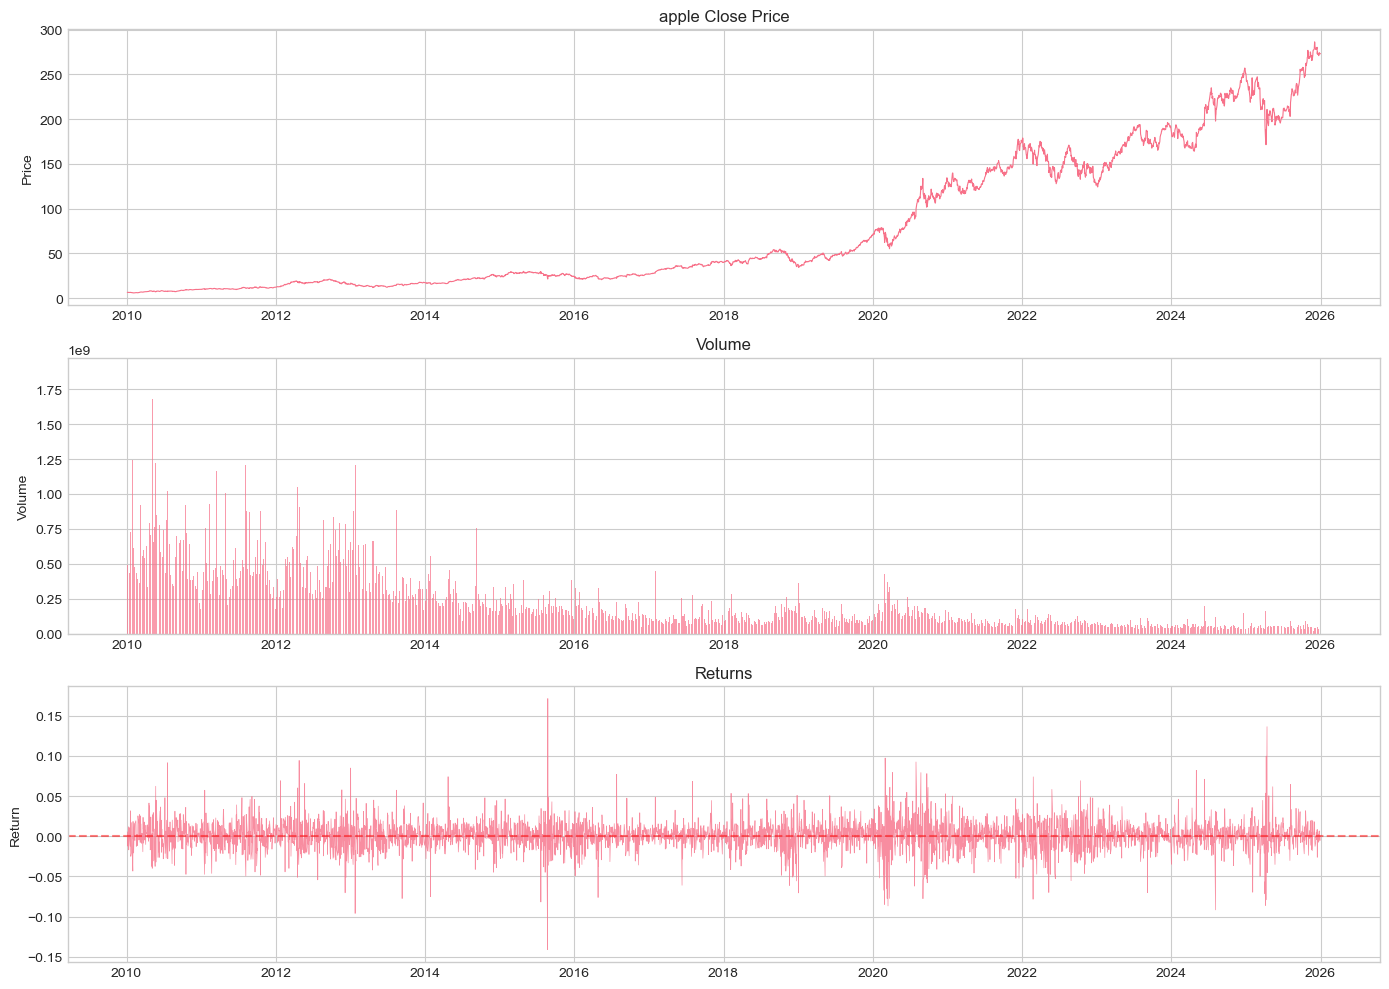

In [10]:
# Price time series
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Close price
axes[0].plot(df.index, df['Close'], linewidth=0.8)
axes[0].set_title(f'{ASSET} Close Price')
axes[0].set_ylabel('Price')

# Volume
if 'Volume' in df.columns:
    axes[1].bar(df.index, df['Volume'], width=1, alpha=0.7)
    axes[1].set_title('Volume')
    axes[1].set_ylabel('Volume')

# Returns
axes[2].plot(df.index, df['returns'], linewidth=0.5, alpha=0.8)
axes[2].axhline(y=0, color='r', linestyle='--', alpha=0.5)
axes[2].set_title('Returns')
axes[2].set_ylabel('Return')

plt.tight_layout()
plt.show()

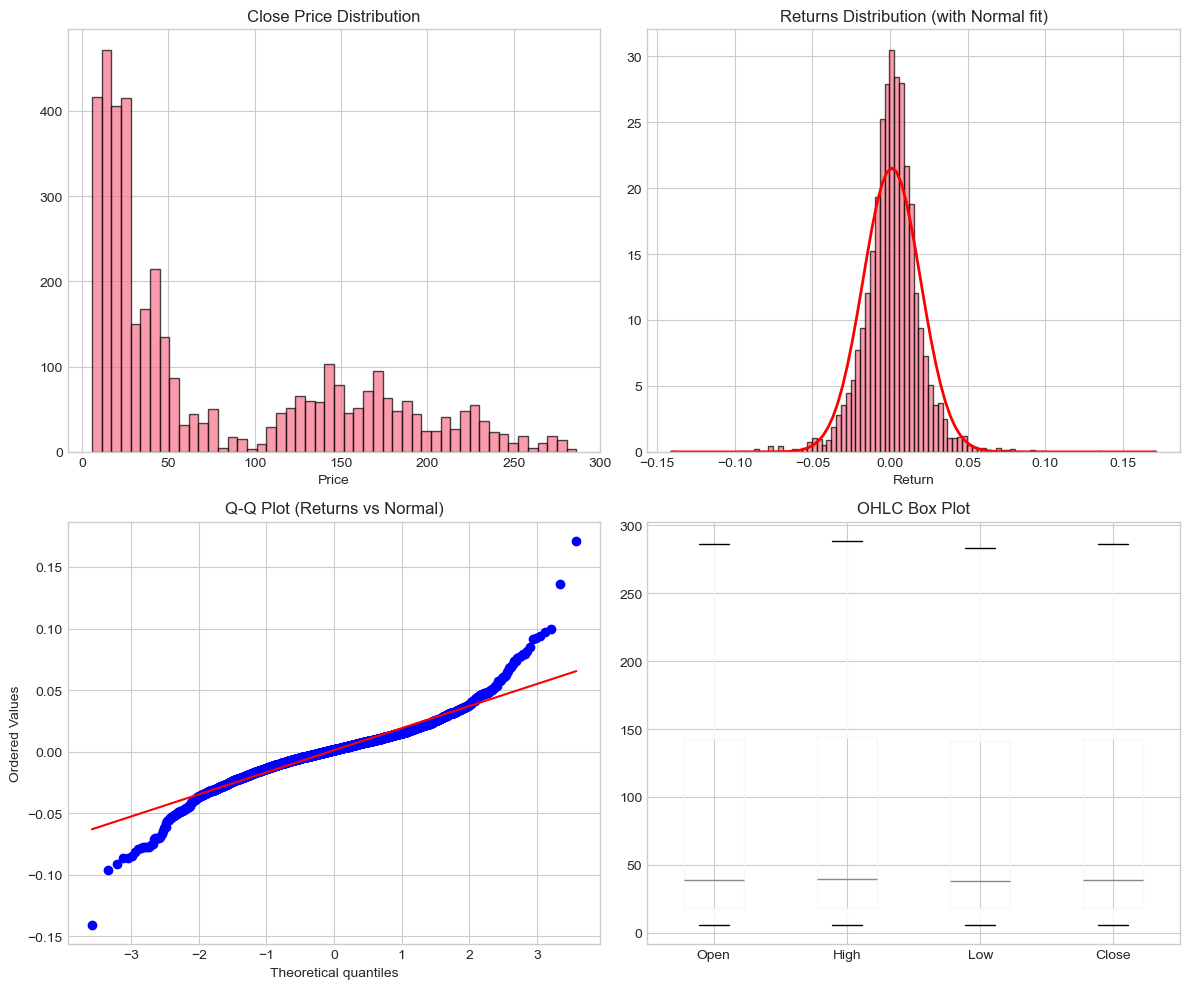

In [11]:
# Distribution plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Close price distribution
axes[0, 0].hist(df['Close'], bins=50, edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Close Price Distribution')
axes[0, 0].set_xlabel('Price')

# Returns distribution
axes[0, 1].hist(returns, bins=100, edgecolor='black', alpha=0.7, density=True)
# Overlay normal distribution
x = np.linspace(returns.min(), returns.max(), 100)
axes[0, 1].plot(x, stats.norm.pdf(x, returns.mean(), returns.std()), 'r-', lw=2)
axes[0, 1].set_title('Returns Distribution (with Normal fit)')
axes[0, 1].set_xlabel('Return')

# Q-Q plot
stats.probplot(returns, dist='norm', plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot (Returns vs Normal)')

# Box plot of OHLC
df[['Open', 'High', 'Low', 'Close']].boxplot(ax=axes[1, 1])
axes[1, 1].set_title('OHLC Box Plot')

plt.tight_layout()
plt.show()

## 5. Correlation Analysis

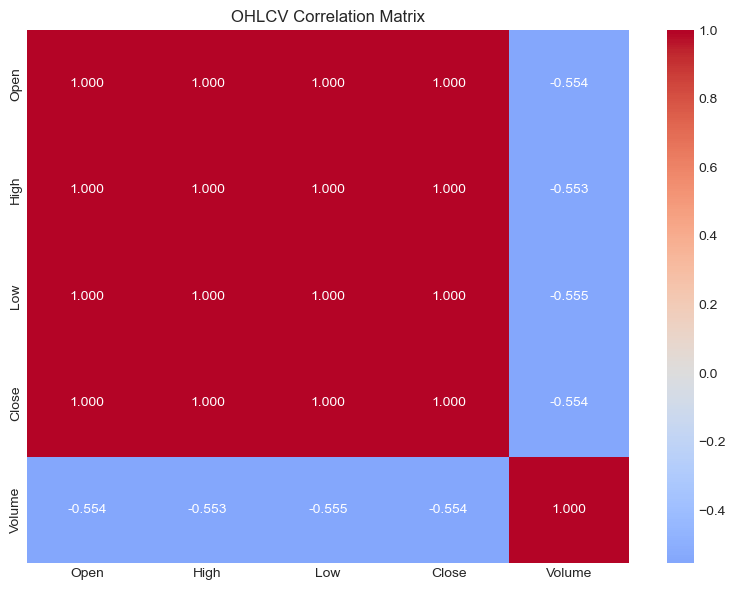

In [12]:
# Correlation matrix
corr_cols = ['Open', 'High', 'Low', 'Close']
if 'Volume' in df.columns:
    corr_cols.append('Volume')

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.3f')
plt.title('OHLCV Correlation Matrix')
plt.tight_layout()
plt.show()

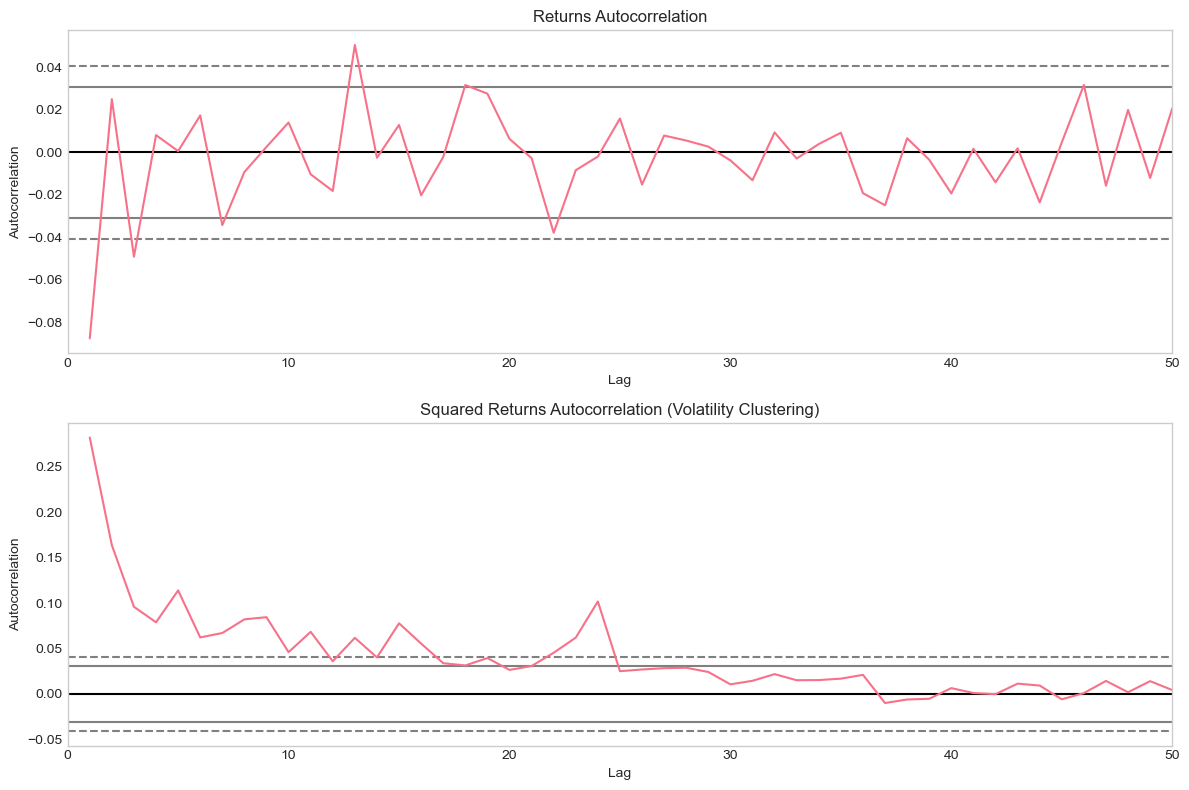

In [13]:
# Autocorrelation of returns
from pandas.plotting import autocorrelation_plot

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Returns autocorrelation
autocorrelation_plot(returns, ax=axes[0])
axes[0].set_title('Returns Autocorrelation')
axes[0].set_xlim([0, 50])

# Squared returns autocorrelation (volatility clustering)
autocorrelation_plot(returns**2, ax=axes[1])
axes[1].set_title('Squared Returns Autocorrelation (Volatility Clustering)')
axes[1].set_xlim([0, 50])

plt.tight_layout()
plt.show()

## 6. Stationarity Tests

In [14]:
from statsmodels.tsa.stattools import adfuller, kpss

def test_stationarity(series, name='Series'):
    """Perform ADF and KPSS tests for stationarity."""
    print(f"\nStationarity Tests for {name}:")
    print("-" * 50)
    
    # ADF Test (H0: unit root exists -> non-stationary)
    adf_result = adfuller(series.dropna(), autolag='AIC')
    print(f"ADF Test:")
    print(f"  Test Statistic: {adf_result[0]:.4f}")
    print(f"  p-value: {adf_result[1]:.4f}")
    print(f"  Critical Values:")
    for key, value in adf_result[4].items():
        print(f"    {key}: {value:.4f}")
    print(f"  Conclusion: {'Stationary' if adf_result[1] < 0.05 else 'Non-Stationary'}")
    
    # KPSS Test (H0: stationary)
    kpss_result = kpss(series.dropna(), regression='c', nlags='auto')
    print(f"\nKPSS Test:")
    print(f"  Test Statistic: {kpss_result[0]:.4f}")
    print(f"  p-value: {kpss_result[1]:.4f}")
    print(f"  Critical Values:")
    for key, value in kpss_result[3].items():
        print(f"    {key}: {value:.4f}")
    print(f"  Conclusion: {'Stationary' if kpss_result[1] > 0.05 else 'Non-Stationary'}")

In [15]:
# Test close price (usually non-stationary)
test_stationarity(df['Close'], 'Close Price')

# Test returns (usually stationary)
test_stationarity(returns, 'Returns')


Stationarity Tests for Close Price:
--------------------------------------------------
ADF Test:
  Test Statistic: 1.2753
  p-value: 0.9965
  Critical Values:
    1%: -3.4320
    5%: -2.8623
    10%: -2.5672
  Conclusion: Non-Stationary

KPSS Test:
  Test Statistic: 8.8232
  p-value: 0.0100
  Critical Values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Conclusion: Non-Stationary

Stationarity Tests for Returns:
--------------------------------------------------


C:\Users\Nabeel\AppData\Local\Temp\ipykernel_7792\1669988607.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series.dropna(), regression='c', nlags='auto')


ADF Test:
  Test Statistic: -38.9302
  p-value: 0.0000
  Critical Values:
    1%: -3.4320
    5%: -2.8623
    10%: -2.5672
  Conclusion: Stationary

KPSS Test:
  Test Statistic: 0.0377
  p-value: 0.1000
  Critical Values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Conclusion: Stationary


C:\Users\Nabeel\AppData\Local\Temp\ipykernel_7792\1669988607.py:19: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(series.dropna(), regression='c', nlags='auto')


## 7. Summary and Conclusions

In [16]:
print("="*60)
print("EDA SUMMARY")
print("="*60)
print(f"\nDataset: {ASSET}")
print(f"Total observations: {len(df):,}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"\nData Quality:")
print(f"  Missing values: {df.isnull().sum().sum()}")
print(f"  Duplicate timestamps: {duplicates}")
print(f"\nPrice Statistics:")
print(f"  Mean close: {df['Close'].mean():.2f}")
print(f"  Std close: {df['Close'].std():.2f}")
print(f"  Min close: {df['Close'].min():.2f}")
print(f"  Max close: {df['Close'].max():.2f}")
print(f"\nReturn Statistics:")
print(f"  Mean: {returns.mean():.6f}")
print(f"  Volatility (std): {returns.std():.6f}")
print(f"  Skewness: {returns.skew():.4f}")
print(f"  Kurtosis: {returns.kurtosis():.4f}")
print("\nKey Observations:")
print("  - Returns show fat tails (excess kurtosis)")
print("  - Volatility clustering observed in squared returns")
print("  - Price series is non-stationary, returns are stationary")

EDA SUMMARY

Dataset: apple
Total observations: 4,024
Date range: 2010-01-04 00:00:00 to 2025-12-31 00:00:00

Data Quality:
  Missing values: 2
  Duplicate timestamps: 0

Price Statistics:
  Mean close: 77.45
  Std close: 74.95
  Min close: 5.77
  Max close: 286.20

Return Statistics:
  Mean: 0.001105
  Volatility (std): 0.018540
  Skewness: 0.0916
  Kurtosis: 6.4012

Key Observations:
  - Returns show fat tails (excess kurtosis)
  - Volatility clustering observed in squared returns
  - Price series is non-stationary, returns are stationary
